# Electricity Consumption Weather Analysis
## Preprocessing, Visualization, and Regression Models

This notebook performs comprehensive analysis on electricity consumption data including:
- Data preprocessing and feature engineering
- Exploratory data analysis with visualizations
- Multiple Linear Regression
- Lasso Regression (L1 Regularization)
- Ridge Regression (L2 Regularization)
- Model comparison and evaluation

## 1. Import Libraries

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
from datetime import datetime

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load Data

In [2]:
# Load the electricity consumption dataset
df = pd.read_csv('electricity_consumption_based_weather_dataset.csv')

print("Dataset shape:", df.shape)
print("\nFirst few rows:")
df.head(10)

Dataset shape: (1433, 6)

First few rows:


,date,AWND,PRCP,TMAX,TMIN,daily_consumption
0,2006-12-16,2.5,0.0,10.6,5.0,1209.176
1,2006-12-17,2.6,0.0,13.3,5.6,3390.460
2,2006-12-18,2.4,0.0,15.0,6.7,2203.826
3,2006-12-19,2.4,0.0,7.2,2.2,1666.194
4,2006-12-20,2.4,0.0,7.2,1.1,2225.748
5,2006-12-21,2.3,0.0,12.2,3.3,1716.624
6,2006-12-22,2.3,11.9,9.4,3.9,2341.338
7,2006-12-23,3.0,19.8,15.0,8.9,4773.386
8,2006-12-24,3.4,0.0,11.1,6.1,2550.012
9,2006-12-25,2.2,9.4,7.2,3.9,2743.120


## 3. Data Exploration and Preprocessing

### 3.1 Basic Data Information

In [3]:
# Basic information about the dataset
print("Dataset Info:")
print(df.info())
print("\n" + "="*70 + "\n")

# Statistical summary
print("Statistical Summary:")
print(df.describe())
print("\n" + "="*70 + "\n")

# Check for missing values
print("Missing Values:")
missing_values = df.isnull().sum()
print(missing_values)
print(f"\nTotal missing values: {missing_values.sum()}")
print("\n" + "="*70 + "\n")

# Check for duplicates
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               1433 non-null   object 
 1   AWND               1418 non-null   float64
 2   PRCP               1433 non-null   float64
 3   TMAX               1433 non-null   float64
 4   TMIN               1433 non-null   float64
 5   daily_consumption  1433 non-null   float64
dtypes: float64(5), object(1)
memory usage: 67.3+ KB
None


Statistical Summary:


              AWND         PRCP         TMAX         TMIN  daily_consumption
count  1418.000000  1433.000000  1433.000000  1433.000000        1433.000000
mean      2.642313     3.800488    17.187509     9.141242        1561.078061
std       1.140021    10.973436    10.136415     9.028417         606.819667
min       0.000000     0.000000    -8.900000   -14.400000          14.218000
25%       1.800000     0.000000     8.900000     2.200000        1165.700000
50%       2.400000     0.000000    17.800000     9.400000        1542.650000
75%       3.300000     1.300000    26.100000    17.200000        1893.608000
max      10.200000   192.300000    39.400000    27.200000        4773.386000


Missing Values:
date                  0
AWND                 15
PRCP                  0
TMAX                  0
TMIN                  0
daily_consumption     0
dtype: int64

Total missing values: 15


Number of duplicate rows: 0


In [4]:
# Display column names and their meanings
print("Column Descriptions:")
print("="*70)
columns_info = {
    'date': 'Date of the observation',
    'AWND': 'Average Wind Speed',
    'PRCP': 'Precipitation (rainfall)',
    'TMAX': 'Maximum Temperature',
    'TMIN': 'Minimum Temperature',
    'daily_consumption': 'Daily Electricity Consumption (Target Variable)'
}

for col, desc in columns_info.items():
    print(f"{col:20s}: {desc}")

Column Descriptions:
date                : Date of the observation
AWND                : Average Wind Speed
PRCP                : Precipitation (rainfall)
TMAX                : Maximum Temperature
TMIN                : Minimum Temperature
daily_consumption   : Daily Electricity Consumption (Target Variable)


### 3.2 Date Feature Engineering

In [5]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Extract date features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek  # Monday=0, Sunday=6
df['day_of_year'] = df['date'].dt.dayofyear
df['week_of_year'] = df['date'].dt.isocalendar().week
df['quarter'] = df['date'].dt.quarter
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

# Create season feature
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

print("Date features extracted successfully!")
print(f"\nDate range: {df['date'].min()} to {df['date'].max()}")
print(f"Total days: {(df['date'].max() - df['date'].min()).days}")
print("\nNew features created:")
print(df[['date', 'year', 'month', 'day', 'day_of_week', 'season', 'is_weekend']].head())

Date features extracted successfully!

Date range: 2006-12-16 00:00:00 to 2010-11-26 00:00:00
Total days: 1441

New features created:
        date  year  month  day  day_of_week  season  is_weekend
0 2006-12-16  2006     12   16            5  Winter           1
1 2006-12-17  2006     12   17            6  Winter           1
2 2006-12-18  2006     12   18            0  Winter           0
3 2006-12-19  2006     12   19            1  Winter           0
4 2006-12-20  2006     12   20            2  Winter           0


### 3.3 Feature Engineering - Temperature Features

In [6]:
# Create additional temperature features
df['temp_range'] = df['TMAX'] - df['TMIN']
df['temp_avg'] = (df['TMAX'] + df['TMIN']) / 2

print("Temperature features created:")
print(df[['TMAX', 'TMIN', 'temp_range', 'temp_avg']].describe())

Temperature features created:
              TMAX         TMIN   temp_range     temp_avg
count  1433.000000  1433.000000  1433.000000  1433.000000
mean     17.187509     9.141242     8.046267    13.164375
std      10.136415     9.028417     3.025356     9.478471
min      -8.900000   -14.400000     1.200000   -10.850000
25%       8.900000     2.200000     5.600000     5.550000
50%      17.800000     9.400000     7.800000    13.600000
75%      26.100000    17.200000    10.000000    21.400000
max      39.400000    27.200000    20.000000    33.300000


### 3.4 Handle Missing Values

In [7]:
# Check for any missing values after feature engineering
print("Missing values after feature engineering:")
print(df.isnull().sum())

# If there are missing values, handle them
if df.isnull().sum().sum() > 0:
    print("\nHandling missing values...")
    # Fill numerical missing values with median
    numerical_cols = df.select_dtypes(include=[np.number]).columns
    for col in numerical_cols:
        if df[col].isnull().sum() > 0:
            df[col].fillna(df[col].median(), inplace=True)
    print("Missing values handled.")
else:
    print("\nNo missing values found!")

Missing values after feature engineering:
date                  0
AWND                 15
PRCP                  0
TMAX                  0
TMIN                  0
daily_consumption     0
year                  0
month                 0
day                   0
day_of_week           0
day_of_year           0
week_of_year          0
quarter               0
is_weekend            0
season                0
temp_range            0
temp_avg              0
dtype: int64

Handling missing values...
Missing values handled.


In [8]:
df['AWND'] = df['AWND'].fillna(df['AWND'].median(), inplace=True)

## 4. Data Visualization

### 4.1 Distribution of Target Variable

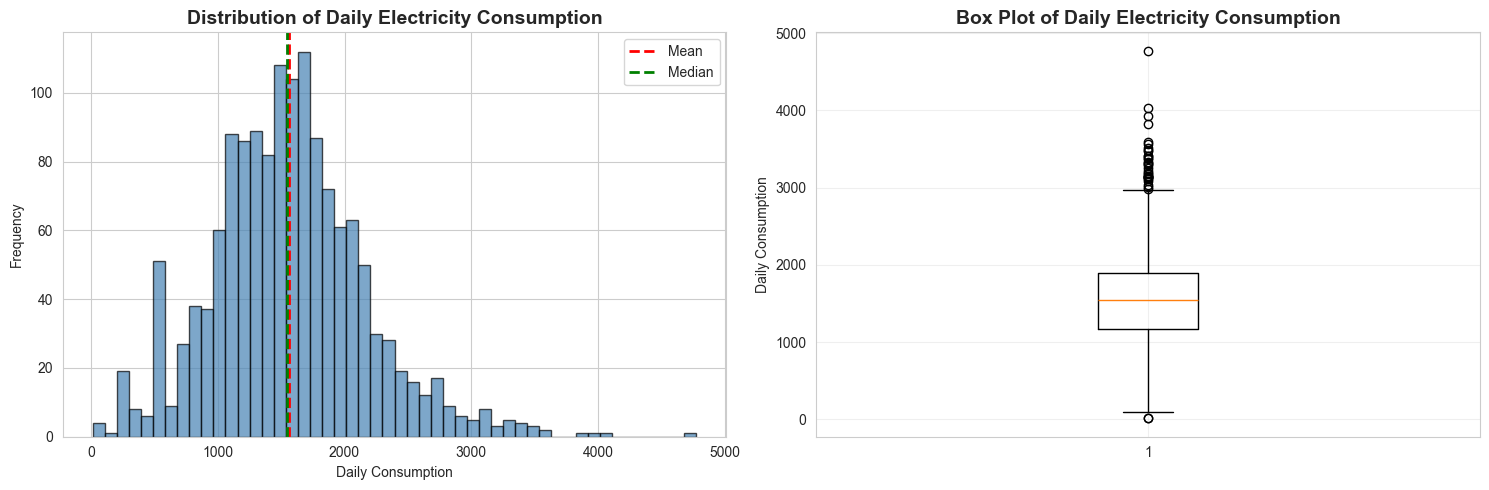

Mean consumption: 1561.08
Median consumption: 1542.65
Std deviation: 606.82


In [9]:
# Distribution of daily electricity consumption
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(df['daily_consumption'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title('Distribution of Daily Electricity Consumption', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Daily Consumption')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['daily_consumption'].mean(), color='red', linestyle='--', linewidth=2, label='Mean')
axes[0].axvline(df['daily_consumption'].median(), color='green', linestyle='--', linewidth=2, label='Median')
axes[0].legend()

# Box plot
axes[1].boxplot(df['daily_consumption'], vert=True)
axes[1].set_title('Box Plot of Daily Electricity Consumption', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Daily Consumption')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean consumption: {df['daily_consumption'].mean():.2f}")
print(f"Median consumption: {df['daily_consumption'].median():.2f}")
print(f"Std deviation: {df['daily_consumption'].std():.2f}")

### 4.2 Time Series Plot

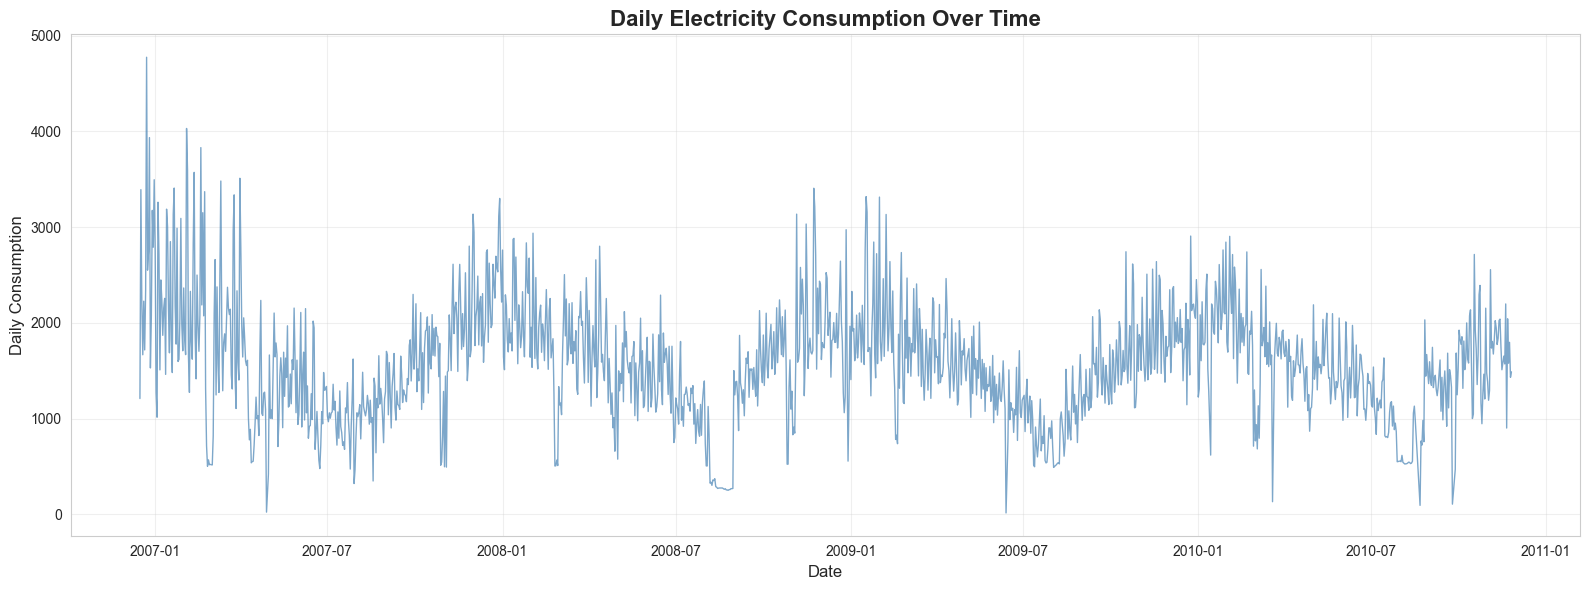

In [10]:
# Time series plot of electricity consumption
plt.figure(figsize=(16, 6))
plt.plot(df['date'], df['daily_consumption'], linewidth=1, color='steelblue', alpha=0.7)
plt.title('Daily Electricity Consumption Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Consumption', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Weather Features Distribution

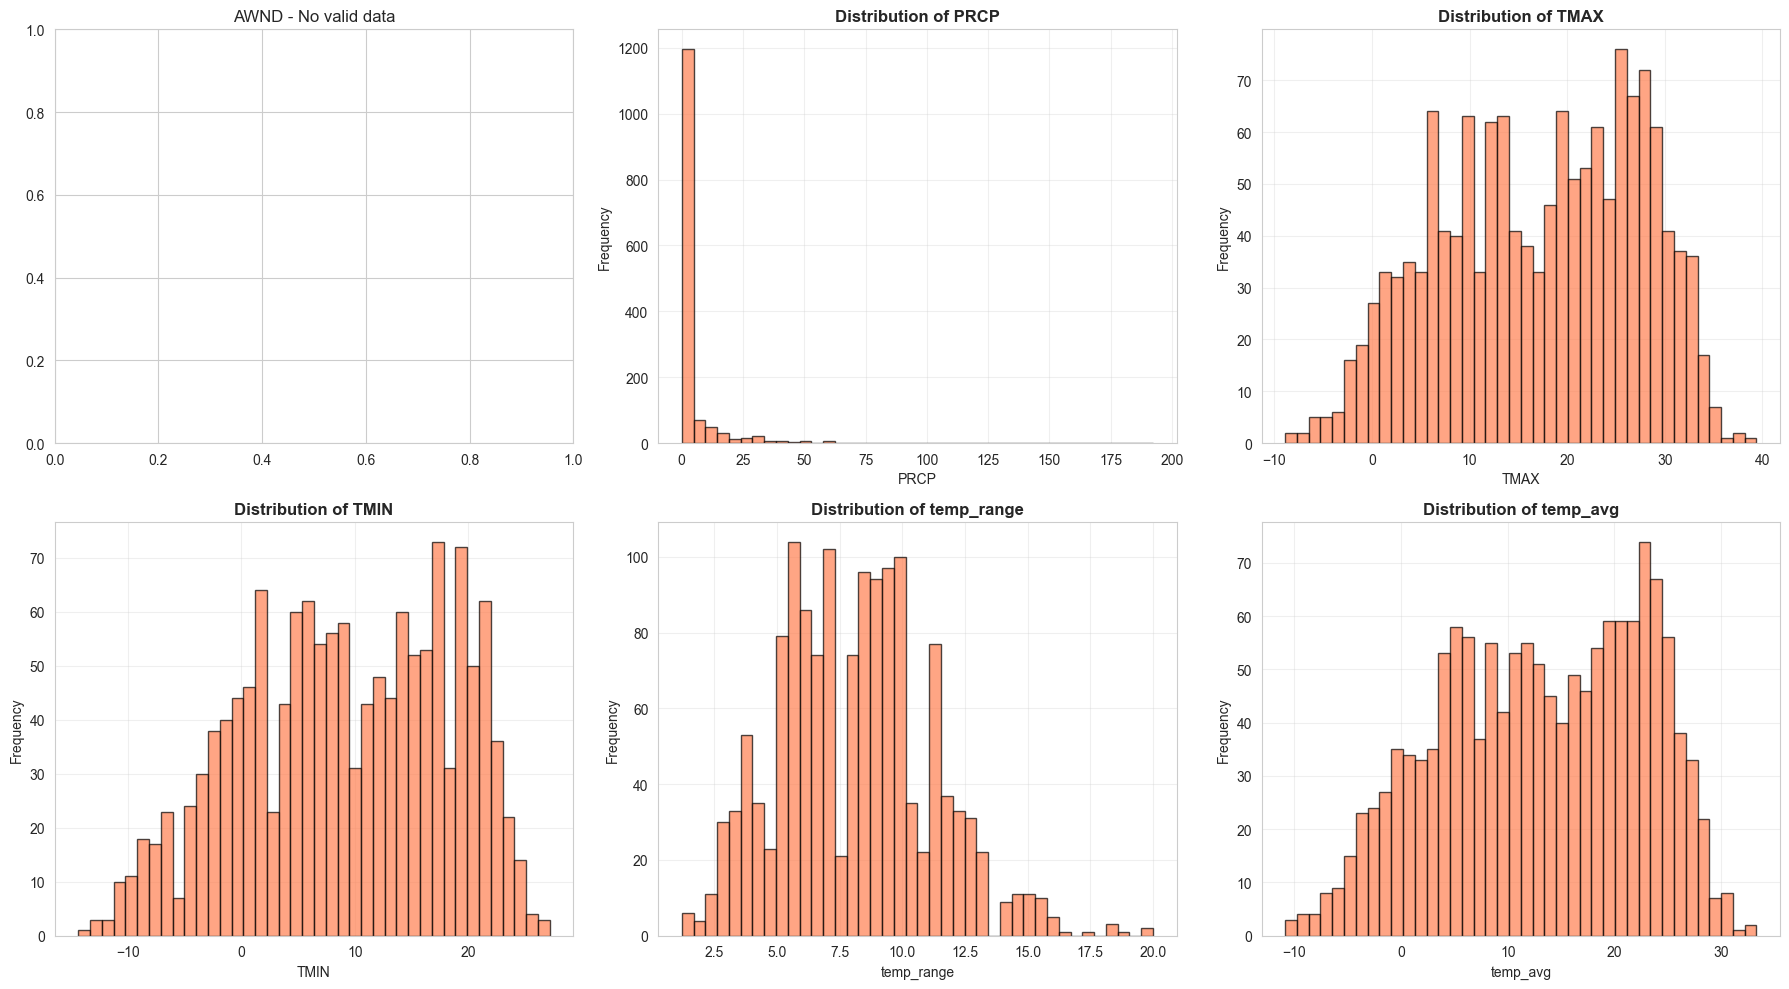

In [12]:
# 
import pandas as pd
import matplotlib.pyplot as plt

# Weather features to visualize
weather_features = [
    'AWND', 'PRCP', 'TMAX',
    'TMIN', 'temp_range', 'temp_avg'
]

# Convert columns to numeric; invalid values become NaN
for col in weather_features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, col in enumerate(weather_features):

    # Remove missing values for plotting
    data = df[col].dropna()

    if not data.empty:
        axes[idx].hist(
            data,
            bins=40,
            edgecolor='black',
            alpha=0.7,
            color='coral'
        )
        axes[idx].set_title(
            f'Distribution of {col}',
            fontsize=12,
            fontweight='bold'
        )
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel('Frequency')
        axes[idx].grid(True, alpha=0.3)
    else:
        axes[idx].set_title(f'{col} - No valid data')

plt.tight_layout()
plt.show()


### 4.4 Correlation Analysis

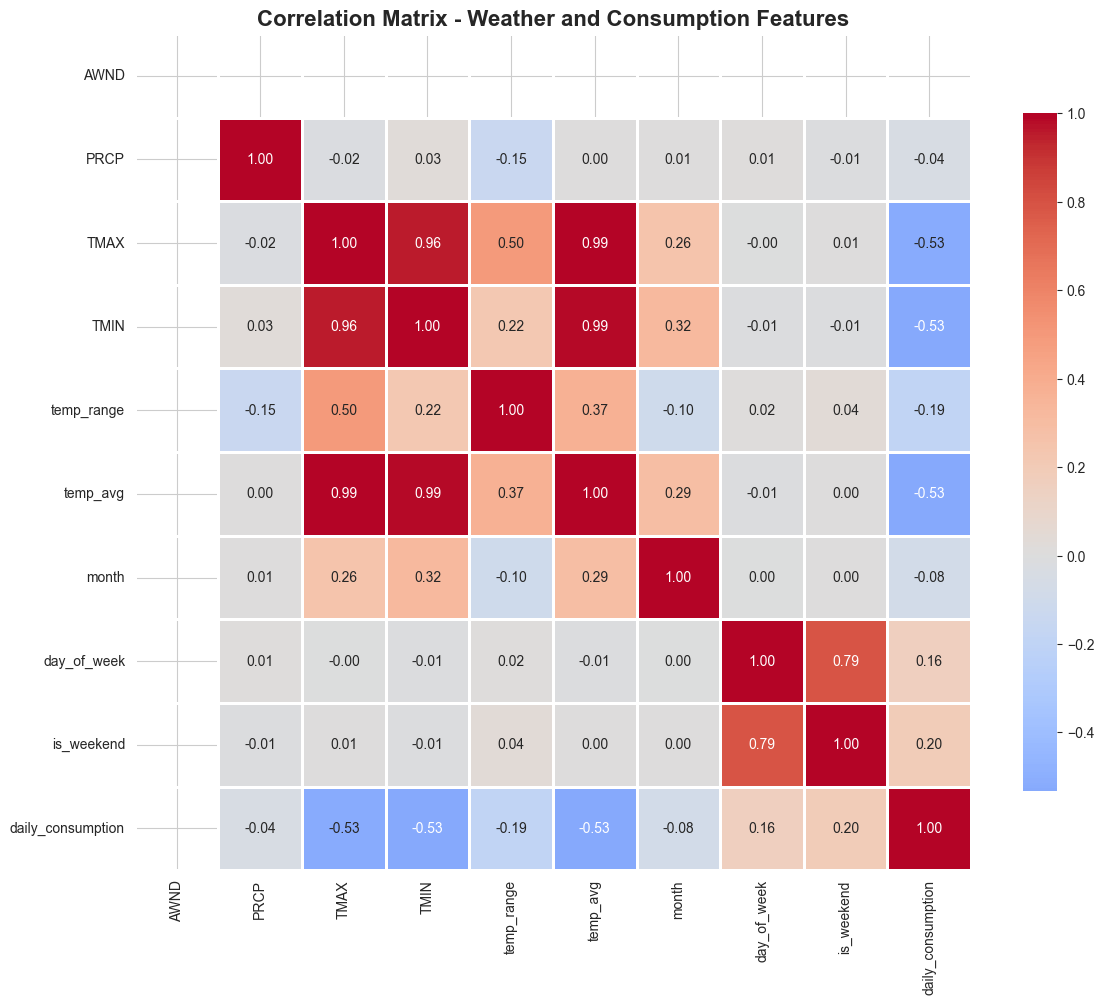


Correlation with Daily Consumption:
daily_consumption    1.000000
is_weekend           0.197607
day_of_week          0.156429
PRCP                -0.036427
month               -0.079215
temp_range          -0.188492
TMAX                -0.525494
TMIN                -0.526822
temp_avg            -0.531890
AWND                      NaN
Name: daily_consumption, dtype: float64


In [13]:
# Correlation matrix for numerical features
numerical_features = ['AWND', 'PRCP', 'TMAX', 'TMIN', 'temp_range', 'temp_avg', 
                      'month', 'day_of_week', 'is_weekend', 'daily_consumption']

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, fmt='.2f')
plt.title('Correlation Matrix - Weather and Consumption Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Display correlations with target variable
print("\nCorrelation with Daily Consumption:")
print("="*50)
target_corr = correlation_matrix['daily_consumption'].sort_values(ascending=False)
print(target_corr)

### 4.5 Feature Relationships with Consumption

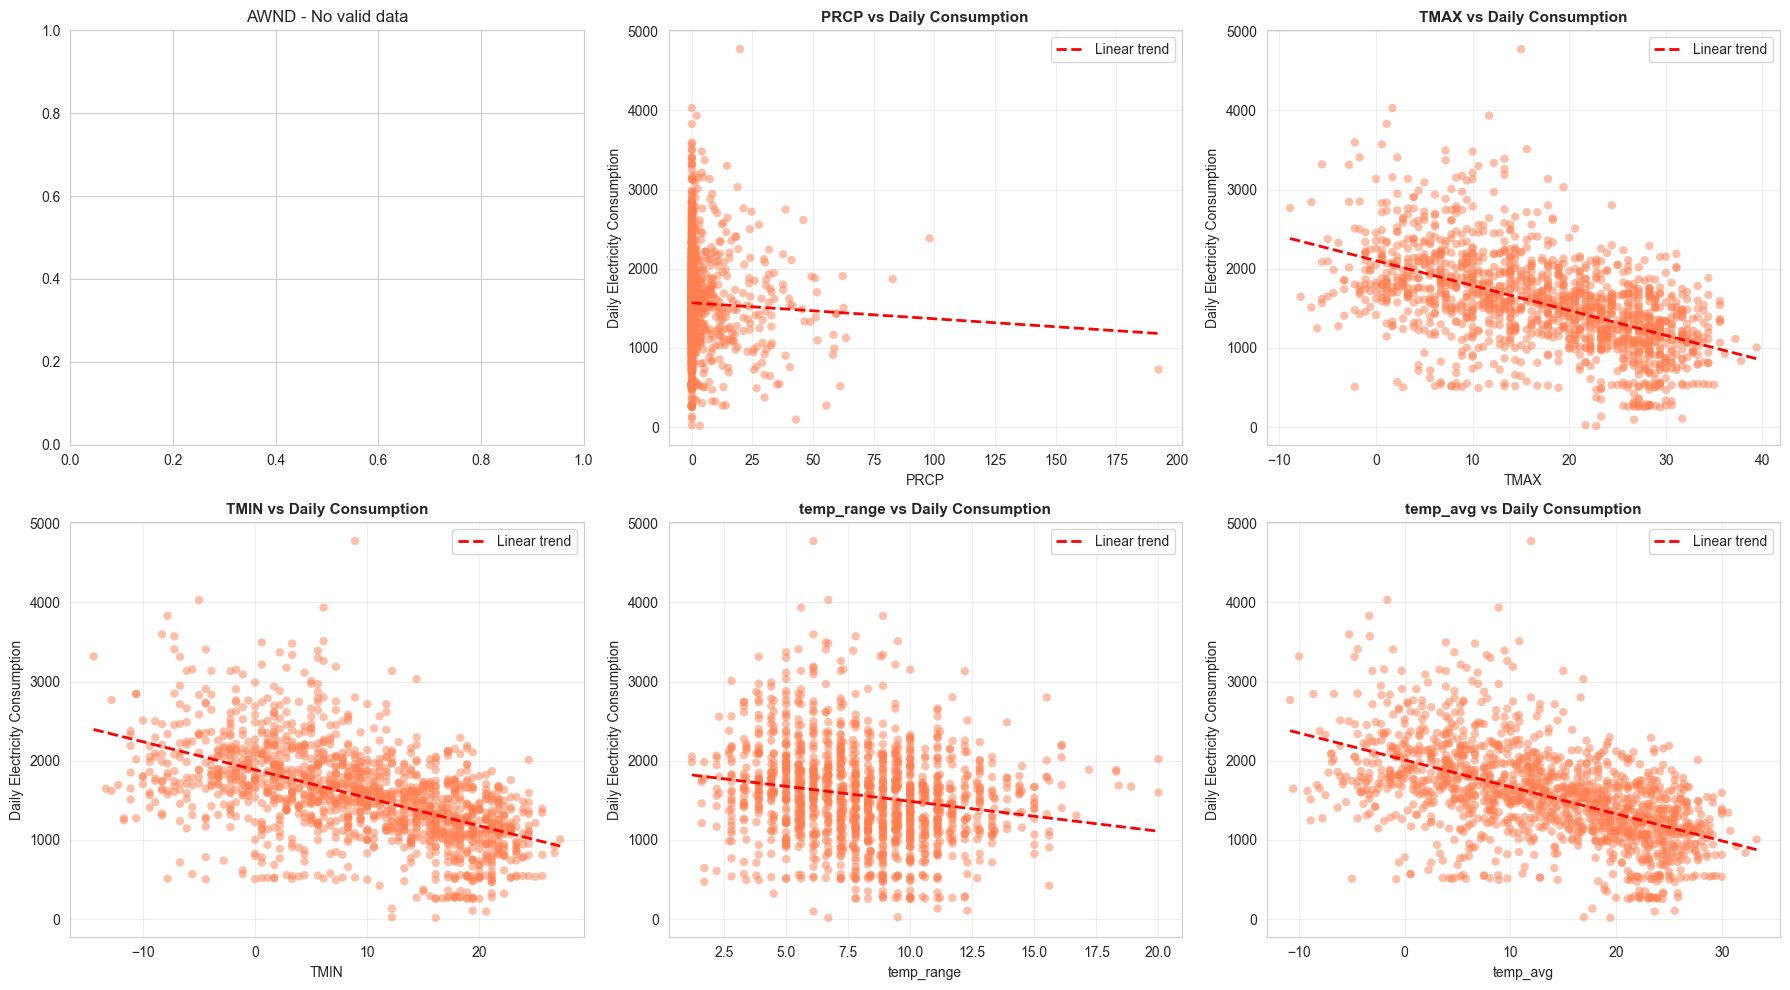

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

weather_features = [
    'AWND', 'PRCP', 'TMAX',
    'TMIN', 'temp_range', 'temp_avg'
]

target_col = 'daily_consumption'

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, col in enumerate(weather_features):

    # Select the two required columns
    data = df[[col, target_col]].copy()

    # Convert values to numeric
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data[target_col] = pd.to_numeric(
        data[target_col], errors='coerce'
    )

    # Replace infinite values and remove missing rows
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    ax = axes[idx]

    if len(data) == 0:
        ax.set_title(f'{col} - No valid data')
        continue

    x = data[col].to_numpy(dtype=float)
    y = data[target_col].to_numpy(dtype=float)

    # Scatter plot
    ax.scatter(
        x, y,
        alpha=0.5,
        color='coral',
        edgecolors='none'
    )

    # Add trend line only when x contains sufficient variation
    if len(data) >= 2 and np.unique(x).size >= 2:
        z = np.polyfit(x, y, 1)
        p = np.poly1d(z)

        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(
            x_line, p(x_line),
            'r--',
            linewidth=2,
            label='Linear trend'
        )
        ax.legend()

    ax.set_title(
        f'{col} vs Daily Consumption',
        fontsize=11,
        fontweight='bold'
    )
    ax.set_xlabel(col)
    ax.set_ylabel('Daily Electricity Consumption')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 4.6 Seasonal and Monthly Analysis

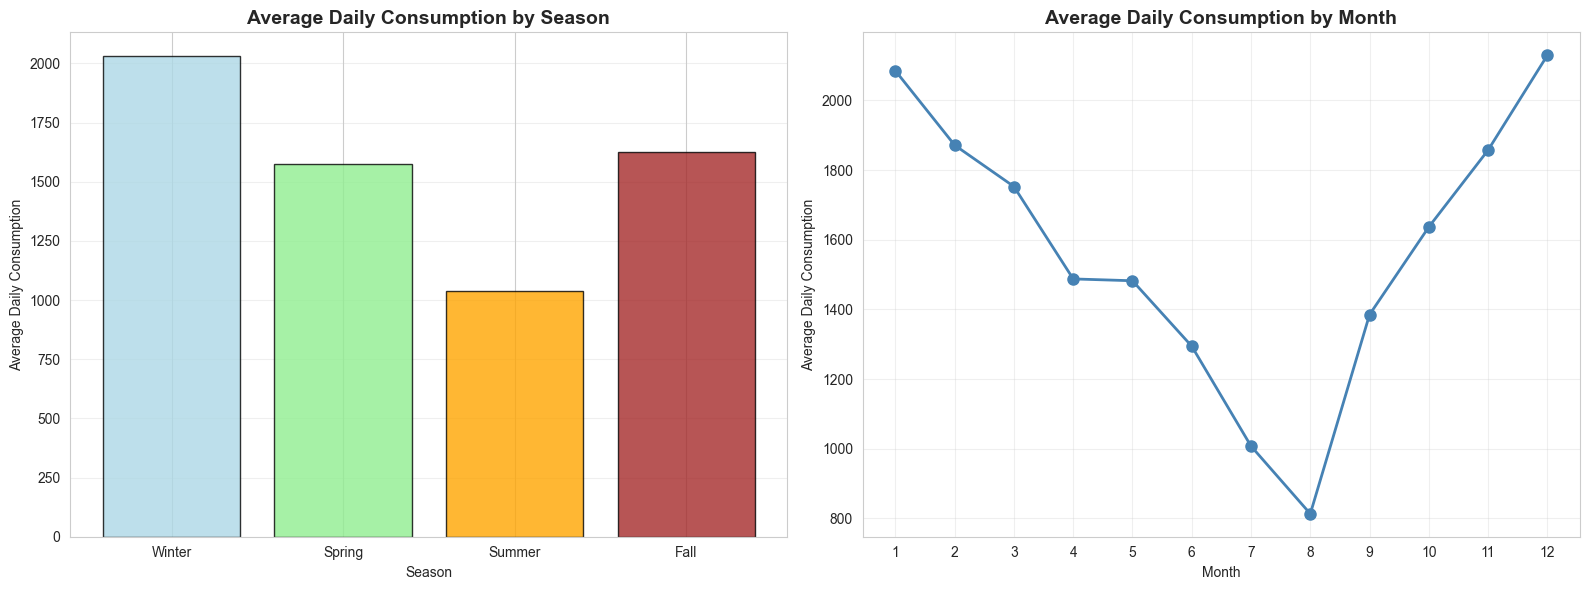

In [16]:
# Consumption by season and month
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# By season
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
df_season = df.groupby('season')['daily_consumption'].mean().reindex(season_order)
axes[0].bar(df_season.index, df_season.values, color=['lightblue', 'lightgreen', 'orange', 'brown'], 
            edgecolor='black', alpha=0.8)
axes[0].set_title('Average Daily Consumption by Season', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Average Daily Consumption')
axes[0].grid(True, alpha=0.3, axis='y')

# By month
df_month = df.groupby('month')['daily_consumption'].mean()
axes[1].plot(df_month.index, df_month.values, marker='o', linewidth=2, markersize=8, color='steelblue')
axes[1].set_title('Average Daily Consumption by Month', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Daily Consumption')
axes[1].set_xticks(range(1, 13))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

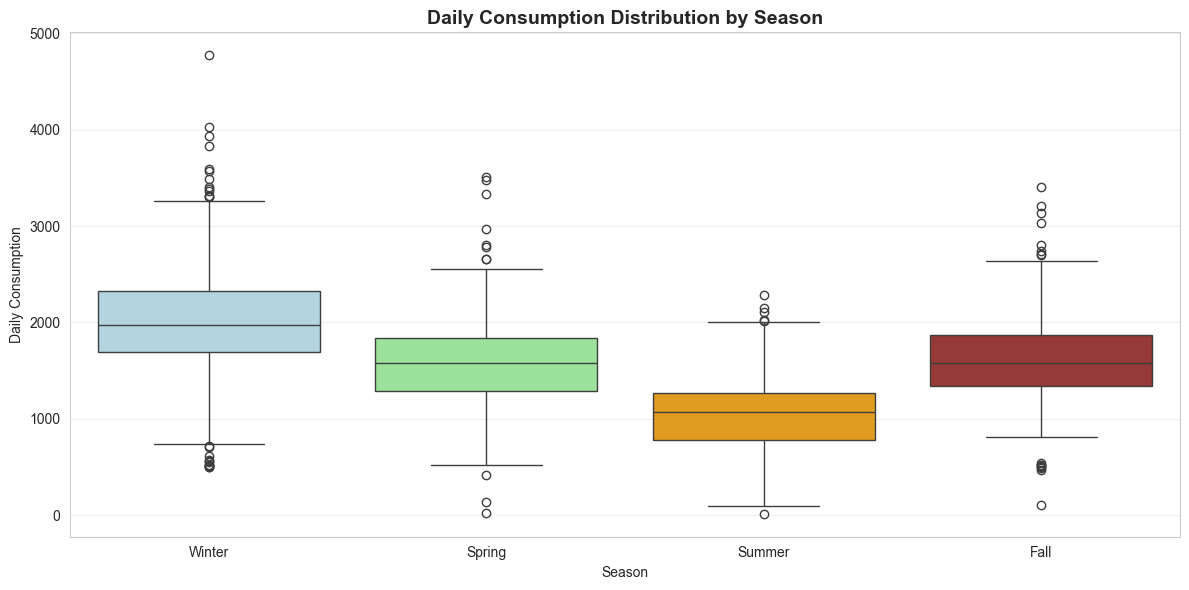

In [17]:
# Box plot by season
plt.figure(figsize=(12, 6))
df_sorted = df.copy()
df_sorted['season'] = pd.Categorical(df_sorted['season'], categories=season_order, ordered=True)
df_sorted = df_sorted.sort_values('season')

sns.boxplot(data=df_sorted, x='season', y='daily_consumption', 
            palette=['lightblue', 'lightgreen', 'orange', 'brown'])
plt.title('Daily Consumption Distribution by Season', fontsize=14, fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Daily Consumption')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 5. Prepare Data for Modeling

In [18]:
# Select features for modeling
feature_columns = ['AWND', 'PRCP', 'TMAX', 'TMIN', 'temp_range', 'temp_avg',
                   'month', 'day_of_week', 'day_of_year', 'quarter', 'is_weekend']

X = df[feature_columns]
y = df['daily_consumption']

print("Features selected for modeling:")
print(feature_columns)
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print("\nFirst few rows of features:")
X.head()

Features selected for modeling:
['AWND', 'PRCP', 'TMAX', 'TMIN', 'temp_range', 'temp_avg', 'month', 'day_of_week', 'day_of_year', 'quarter', 'is_weekend']

X shape: (1433, 11)
y shape: (1433,)

First few rows of features:


,AWND,PRCP,TMAX,TMIN,temp_range,temp_avg,month,day_of_week,day_of_year,quarter,is_weekend
0,NaN,0.0,10.6,5.0,5.6,7.80,12,5,350,4,1
1,NaN,0.0,13.3,5.6,7.7,9.45,12,6,351,4,1
2,NaN,0.0,15.0,6.7,8.3,10.85,12,0,352,4,0
3,NaN,0.0,7.2,2.2,5.0,4.70,12,1,353,4,0
4,NaN,0.0,7.2,1.1,6.1,4.15,12,2,354,4,0


In [19]:
df['AWND'].isna().value_counts()

AWND
True    1433
Name: count, dtype: int64

In [20]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"\nTraining set date range: {df.loc[X_train.index, 'date'].min()} to {df.loc[X_train.index, 'date'].max()}")
print(f"Test set date range: {df.loc[X_test.index, 'date'].min()} to {df.loc[X_test.index, 'date'].max()}")

Training set size: 1146 samples
Test set size: 287 samples

Training set date range: 2006-12-16 00:00:00 to 2010-11-26 00:00:00
Test set date range: 2007-01-08 00:00:00 to 2010-11-17 00:00:00


In [21]:
# Feature scaling (important for Lasso and Ridge regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully!")
print(f"\nScaled features mean (should be ~0): {X_train_scaled.mean(axis=0)}")
print(f"\nScaled features std (should be ~1): {X_train_scaled.std(axis=0)}")

Features scaled successfully!

Scaled features mean (should be ~0): [            nan  0.00000000e+00 -1.73605555e-16  1.51904861e-16
  6.85121922e-16  7.13022815e-17 -8.37026783e-17 -5.42517359e-18
 -8.06025791e-17  2.17006944e-17 -7.75024799e-18]

Scaled features std (should be ~1): [nan  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.]


## 6. Multiple Linear Regression

### 6.1 Train Multiple Linear Regression Model

In [24]:

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Prepare training features and target
X_fixed = X_train.copy()

if not isinstance(X_fixed, pd.DataFrame):
    X_fixed = pd.DataFrame(X_fixed, columns=feature_columns)

y_fixed = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_fixed.index,
    name='daily_consumption'
)

# 2. Convert features to numeric and handle infinite values
X_fixed = X_fixed.apply(pd.to_numeric, errors='coerce')
X_fixed = X_fixed.replace([np.inf, -np.inf], np.nan)

# 3. Remove rows with invalid target values
valid = y_fixed.notna() & np.isfinite(y_fixed)
X_fixed = X_fixed.loc[valid].copy()
y_fixed = y_fixed.loc[valid].copy()

# 4. Remove columns containing only missing values
empty_cols = X_fixed.columns[X_fixed.isna().all()].tolist()

if empty_cols:
    print("Removing completely empty columns:", empty_cols)
    X_fixed = X_fixed.drop(columns=empty_cols)

# 5. Impute remaining missing values
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X_fixed)

# Use the feature names retained by the imputer
feature_names = imputer.get_feature_names_out()

# 6. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_imputed)

# 7. Train Multiple Linear Regression
mlr_model = LinearRegression()
mlr_model.fit(X_train_scaled, y_fixed)

print("\nMultiple Linear Regression Model Trained Successfully!")
print(f"Intercept: {mlr_model.intercept_:.2f}")

# 8. Display correctly matched coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': mlr_model.coef_.ravel()
})

coef_df['Absolute Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(
    'Absolute Coefficient',
    ascending=False
).drop(columns='Absolute Coefficient')

print("\nFeature Coefficients:")
print("=" * 50)
print(coef_df.to_string(index=False))

# 9. Verify data quality
print("\nTraining samples:", len(y_fixed))
print("Features used:", len(feature_names))
print("Coefficients generated:", len(mlr_model.coef_.ravel()))
print("Remaining NaN values:", np.isnan(X_train_scaled).sum())


Removing completely empty columns: ['AWND']

Multiple Linear Regression Model Trained Successfully!
Intercept: 1561.87

Feature Coefficients:
    Feature  Coefficient
 is_weekend   127.550900
       TMIN  -117.532610
   temp_avg  -110.659699
day_of_year   108.001645
       TMAX  -102.210264
    quarter   -84.922290
      month    34.961977
       PRCP   -20.584186
 temp_range     9.439993
day_of_week    -6.156273

Training samples: 1146
Features used: 10
Coefficients generated: 10
Remaining NaN values: 0


### 6.2 Evaluate Multiple Linear Regression

In [26]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from sklearn.model_selection import cross_val_score

# 1. Prepare test features using the same columns as training
X_test_fixed = X_test.copy()

if not isinstance(X_test_fixed, pd.DataFrame):
    X_test_fixed = pd.DataFrame(
        X_test_fixed,
        columns=feature_columns
    )

# Match the training feature columns and their order
X_test_fixed = X_test_fixed.reindex(
    columns=X_fixed.columns
)

# 2. Convert values to numeric and handle infinities
X_test_fixed = X_test_fixed.apply(
    pd.to_numeric, errors='coerce'
)
X_test_fixed = X_test_fixed.replace(
    [np.inf, -np.inf], np.nan
)

# 3. Use the already-fitted imputer and scaler
X_test_imputed = imputer.transform(X_test_fixed)
X_test_scaled = scaler.transform(X_test_imputed)

# 4. Align test targets with valid rows
y_test_fixed = pd.Series(
    np.asarray(y_test).ravel(),
    index=X_test.index,
    name='daily_consumption'
)

valid_test = (
    y_test_fixed.notna()
    & np.isfinite(y_test_fixed)
)

X_test_scaled = X_test_scaled[valid_test.to_numpy()]
y_test_fixed = y_test_fixed.loc[valid_test]

# 5. Make predictions
y_pred_train_mlr = mlr_model.predict(X_train_scaled)
y_pred_test_mlr = mlr_model.predict(X_test_scaled)

# 6. Calculate training metrics
train_r2_mlr = r2_score(y_fixed, y_pred_train_mlr)
train_rmse_mlr = np.sqrt(
    mean_squared_error(y_fixed, y_pred_train_mlr)
)
train_mae_mlr = mean_absolute_error(
    y_fixed, y_pred_train_mlr
)

# 7. Calculate test metrics
test_r2_mlr = r2_score(y_test_fixed, y_pred_test_mlr)
test_rmse_mlr = np.sqrt(
    mean_squared_error(y_test_fixed, y_pred_test_mlr)
)
test_mae_mlr = mean_absolute_error(
    y_test_fixed, y_pred_test_mlr
)

# 8. Five-fold cross-validation
cv_scores_mlr = cross_val_score(
    mlr_model,
    X_train_scaled,
    y_fixed,
    cv=5,
    scoring='r2'
)

# 9. Display results
print("=" * 70)
print("MULTIPLE LINEAR REGRESSION - MODEL PERFORMANCE")
print("=" * 70)

print("\nTraining Set:")
print(f"  R² Score: {train_r2_mlr:.6f}")
print(f"  RMSE:     {train_rmse_mlr:.2f}")
print(f"  MAE:      {train_mae_mlr:.2f}")

print("\nTest Set:")
print(f"  R² Score: {test_r2_mlr:.6f}")
print(f"  RMSE:     {test_rmse_mlr:.2f}")
print(f"  MAE:      {test_mae_mlr:.2f}")

print("\n5-Fold Cross-Validation:")
print(f"  Mean R² Score: {cv_scores_mlr.mean():.6f}")
print(f"  Std R² Score:  {cv_scores_mlr.std():.6f}")

print("=" * 70)


MULTIPLE LINEAR REGRESSION - MODEL PERFORMANCE

Training Set:
  R² Score: 0.319701
  RMSE:     497.29
  MAE:      364.62

Test Set:
  R² Score: 0.369206
  RMSE:     493.29
  MAE:      373.56

5-Fold Cross-Validation:
  Mean R² Score: 0.302180
  Std R² Score:  0.034360


## 7. Lasso Regression (L1 Regularization)

### 7.1 Hyperparameter Tuning for Lasso

In [27]:
# Grid search for optimal alpha
alphas_lasso = np.logspace(-4, 2, 50)

lasso_model = Lasso(max_iter=10000, random_state=42)
grid_search_lasso = GridSearchCV(lasso_model, {'alpha': alphas_lasso}, 
                                  cv=5, scoring='r2', n_jobs=-1)
grid_search_lasso.fit(X_train_scaled, y_train)

best_alpha_lasso = grid_search_lasso.best_params_['alpha']

print("Hyperparameter Tuning for Lasso Regression")
print("="*60)
print(f"Best alpha: {best_alpha_lasso:.6f}")
print(f"Best cross-validation R² score: {grid_search_lasso.best_score_:.6f}")

Hyperparameter Tuning for Lasso Regression
Best alpha: 5.963623
Best cross-validation R² score: 0.306311


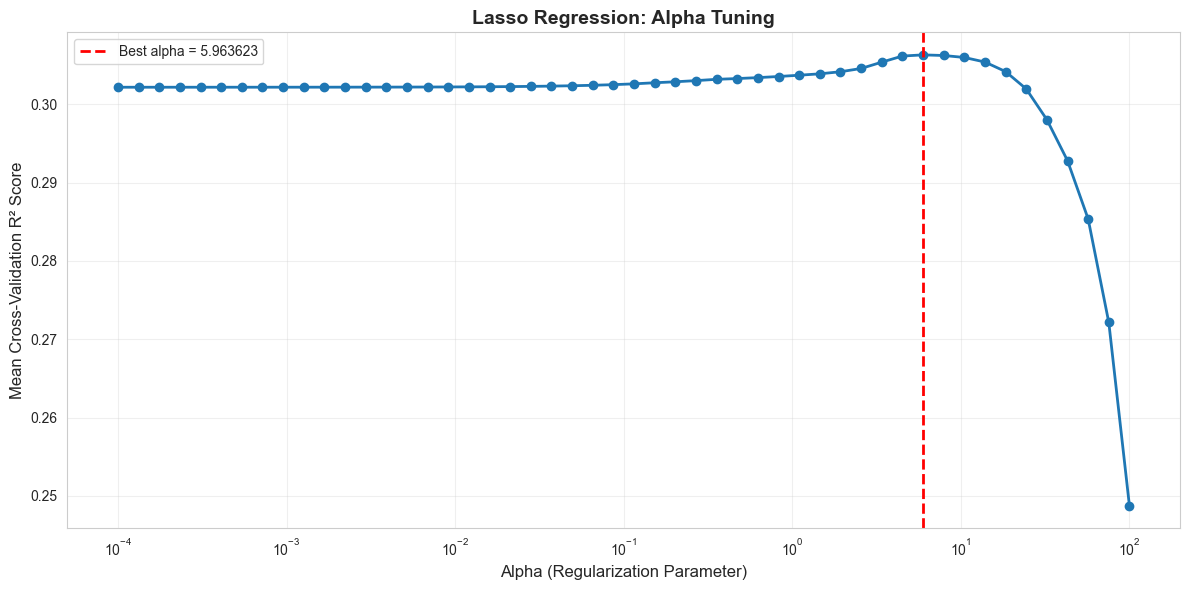

In [28]:
# Visualize alpha tuning
results_lasso = pd.DataFrame(grid_search_lasso.cv_results_)

plt.figure(figsize=(12, 6))
plt.plot(results_lasso['param_alpha'], results_lasso['mean_test_score'], 
         marker='o', linewidth=2, markersize=6)
plt.axvline(best_alpha_lasso, color='r', linestyle='--', linewidth=2, 
            label=f'Best alpha = {best_alpha_lasso:.6f}')
plt.xscale('log')
plt.xlabel('Alpha (Regularization Parameter)', fontsize=12)
plt.ylabel('Mean Cross-Validation R² Score', fontsize=12)
plt.title('Lasso Regression: Alpha Tuning', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Train Lasso Regression Model

In [33]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso

# 1. Train Lasso with the best alpha
lasso_best = Lasso(
    alpha=best_alpha_lasso,
    max_iter=10000,
    random_state=42
)

lasso_best.fit(X_train_scaled, np.asarray(y_fixed).ravel())

print("Lasso Regression Model Trained Successfully!")
print(f"\nAlpha (regularization strength): {best_alpha_lasso:.6f}")
print(f"Intercept: {lasso_best.intercept_:.2f}")

# 2. Get the correct feature names
# X_train_scaled was created from X_imputed
lasso_feature_names = list(feature_names)
lasso_coefficients = np.asarray(lasso_best.coef_).ravel()

# Verify dimensions
print("\nNumber of features:", len(lasso_feature_names))
print("Number of coefficients:", len(lasso_coefficients))

# 3. Display coefficients
if len(lasso_feature_names) != len(lasso_coefficients):
    raise ValueError(
        "Feature names and coefficients differ in length. "
        "Check the preprocessing and model input."
    )

lasso_coef_df = pd.DataFrame({
    "Feature": lasso_feature_names,
    "Coefficient": lasso_coefficients
})

lasso_coef_df = lasso_coef_df.sort_values(
    "Coefficient",
    key=abs,
    ascending=False
)

print("\nLasso Regression Coefficients:")
print("=" * 60)
print(lasso_coef_df.to_string(index=False))

# 4. Count eliminated features
zero_coefs = np.isclose(lasso_coefficients, 0).sum()
nonzero_coefs = len(lasso_coefficients) - zero_coefs

print(f"\nNumber of features with zero coefficients: {zero_coefs}")
print(f"Number of non-zero coefficients: {nonzero_coefs}")
print("=" * 60)


Lasso Regression Model Trained Successfully!

Alpha (regularization strength): 5.963623
Intercept: 1561.87

Number of features: 10
Number of coefficients: 10

Lasso Regression Coefficients:
    Feature  Coefficient
   temp_avg  -234.596071
 is_weekend   116.954917
       TMIN   -84.504011
day_of_year    52.921576
       PRCP   -14.741712
       TMAX    -0.000000
      month     0.000000
 temp_range    -0.000000
day_of_week     0.000000
    quarter     0.000000

Number of features with zero coefficients: 5
Number of non-zero coefficients: 5


### 7.3 Evaluate Lasso Regression

In [34]:
# Make predictions
y_pred_train_lasso = lasso_best.predict(X_train_scaled)
y_pred_test_lasso = lasso_best.predict(X_test_scaled)

# Calculate metrics
train_r2_lasso = r2_score(y_train, y_pred_train_lasso)
test_r2_lasso = r2_score(y_test, y_pred_test_lasso)
train_rmse_lasso = np.sqrt(mean_squared_error(y_train, y_pred_train_lasso))
test_rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_test_lasso))
train_mae_lasso = mean_absolute_error(y_train, y_pred_train_lasso)
test_mae_lasso = mean_absolute_error(y_test, y_pred_test_lasso)

# Cross-validation score
cv_scores_lasso = cross_val_score(lasso_best, X_train_scaled, y_train, cv=5, 
                                   scoring='r2')

print("="*70)
print("LASSO REGRESSION - MODEL PERFORMANCE")
print("="*70)
print(f"\nTraining Set:")
print(f"  R² Score: {train_r2_lasso:.6f}")
print(f"  RMSE: {train_rmse_lasso:.2f}")
print(f"  MAE: {train_mae_lasso:.2f}")
print(f"\nTest Set:")
print(f"  R² Score: {test_r2_lasso:.6f}")
print(f"  RMSE: {test_rmse_lasso:.2f}")
print(f"  MAE: {test_mae_lasso:.2f}")
print(f"\n5-Fold Cross-Validation:")
print(f"  Mean R² Score: {cv_scores_lasso.mean():.6f}")
print(f"  Std R² Score: {cv_scores_lasso.std():.6f}")
print("="*70)

LASSO REGRESSION - MODEL PERFORMANCE

Training Set:
  R² Score: 0.318021
  RMSE: 497.91
  MAE: 365.01

Test Set:
  R² Score: 0.368721
  RMSE: 493.48
  MAE: 374.99

5-Fold Cross-Validation:
  Mean R² Score: 0.306311
  Std R² Score: 0.027296


## 8. Ridge Regression (L2 Regularization)

### 8.1 Hyperparameter Tuning for Ridge

In [35]:
# Grid search for optimal alpha
alphas_ridge = np.logspace(-4, 4, 50)

ridge_model = Ridge(max_iter=10000, random_state=42)
grid_search_ridge = GridSearchCV(ridge_model, {'alpha': alphas_ridge}, 
                                  cv=5, scoring='r2', n_jobs=-1)
grid_search_ridge.fit(X_train_scaled, y_train)

best_alpha_ridge = grid_search_ridge.best_params_['alpha']

print("Hyperparameter Tuning for Ridge Regression")
print("="*60)
print(f"Best alpha: {best_alpha_ridge:.6f}")
print(f"Best cross-validation R² score: {grid_search_ridge.best_score_:.6f}")

Hyperparameter Tuning for Ridge Regression
Best alpha: 51.794747
Best cross-validation R² score: 0.304925


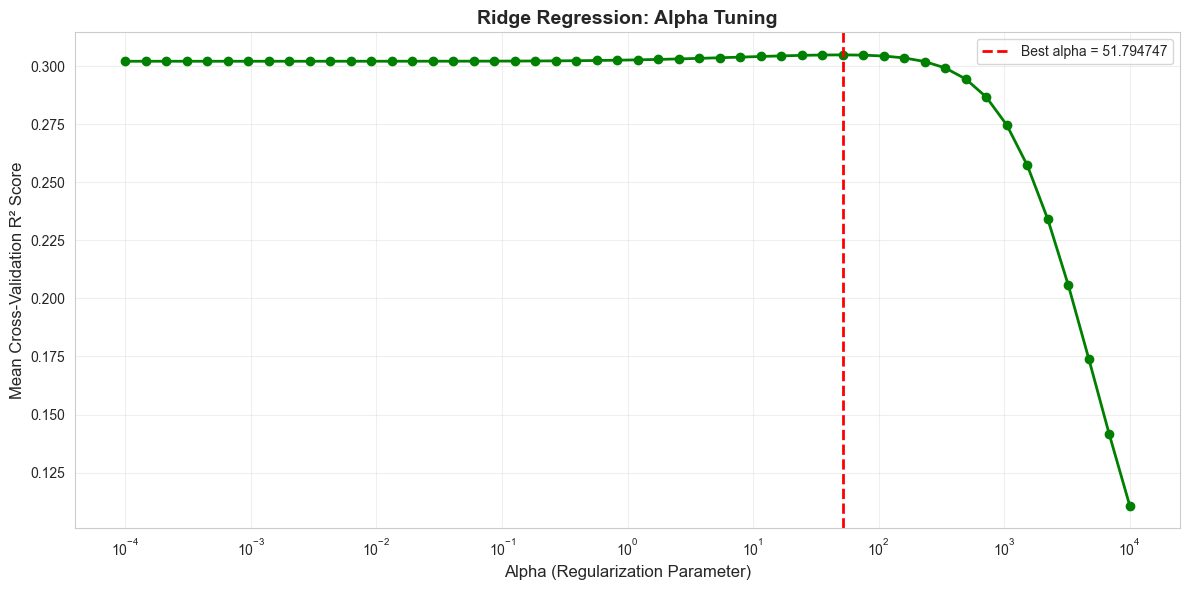

In [36]:
# Visualize alpha tuning
results_ridge = pd.DataFrame(grid_search_ridge.cv_results_)

plt.figure(figsize=(12, 6))
plt.plot(results_ridge['param_alpha'], results_ridge['mean_test_score'], 
         marker='o', linewidth=2, markersize=6, color='green')
plt.axvline(best_alpha_ridge, color='r', linestyle='--', linewidth=2, 
            label=f'Best alpha = {best_alpha_ridge:.6f}')
plt.xscale('log')
plt.xlabel('Alpha (Regularization Parameter)', fontsize=12)
plt.ylabel('Mean Cross-Validation R² Score', fontsize=12)
plt.title('Ridge Regression: Alpha Tuning', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 8.2 Train Ridge Regression Model

In [38]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

# 1. Train Ridge with the best alpha
ridge_best = Ridge(
    alpha=best_alpha_ridge,
    max_iter=10000,
    random_state=42
)

ridge_best.fit(X_train_scaled, np.asarray(y_fixed).ravel())

print("Ridge Regression Model Trained Successfully!")
print(f"\nAlpha (regularization strength): {best_alpha_ridge:.6f}")
print(f"Intercept: {ridge_best.intercept_:.2f}")

# 2. Use feature names from the preprocessing step
ridge_feature_names = list(feature_names)
ridge_coefficients = np.asarray(ridge_best.coef_).ravel()

# 3. Verify matching dimensions
print("\nNumber of features:", len(ridge_feature_names))
print("Number of coefficients:", len(ridge_coefficients))

assert len(ridge_feature_names) == len(ridge_coefficients), (
    "Feature names and coefficients do not match. "
    "Check the preprocessing steps."
)

# 4. Display coefficients
ridge_coef_df = pd.DataFrame({
    'Feature': ridge_feature_names,
    'Coefficient': ridge_coefficients
}).sort_values(
    'Coefficient',
    key=abs,
    ascending=False
)

print("\nRidge Regression Coefficients:")
print("=" * 60)
print(ridge_coef_df.to_string(index=False))
print("=" * 60)


Ridge Regression Model Trained Successfully!

Alpha (regularization strength): 51.794747
Intercept: 1561.87

Number of features: 10
Number of coefficients: 10

Ridge Regression Coefficients:
    Feature  Coefficient
       TMIN  -115.235638
 is_weekend   115.075737
   temp_avg  -108.795229
       TMAX  -100.771194
day_of_year    48.673906
      month    39.051951
    quarter   -31.839164
       PRCP   -20.257493
 temp_range     7.392187
day_of_week     3.483854


### 8.3 Evaluate Ridge Regression

In [39]:
# Make predictions
y_pred_train_ridge = ridge_best.predict(X_train_scaled)
y_pred_test_ridge = ridge_best.predict(X_test_scaled)

# Calculate metrics
train_r2_ridge = r2_score(y_train, y_pred_train_ridge)
test_r2_ridge = r2_score(y_test, y_pred_test_ridge)
train_rmse_ridge = np.sqrt(mean_squared_error(y_train, y_pred_train_ridge))
test_rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_test_ridge))
train_mae_ridge = mean_absolute_error(y_train, y_pred_train_ridge)
test_mae_ridge = mean_absolute_error(y_test, y_pred_test_ridge)

# Cross-validation score
cv_scores_ridge = cross_val_score(ridge_best, X_train_scaled, y_train, cv=5, 
                                   scoring='r2')

print("="*70)
print("RIDGE REGRESSION - MODEL PERFORMANCE")
print("="*70)
print(f"\nTraining Set:")
print(f"  R² Score: {train_r2_ridge:.6f}")
print(f"  RMSE: {train_rmse_ridge:.2f}")
print(f"  MAE: {train_mae_ridge:.2f}")
print(f"\nTest Set:")
print(f"  R² Score: {test_r2_ridge:.6f}")
print(f"  RMSE: {test_rmse_ridge:.2f}")
print(f"  MAE: {test_mae_ridge:.2f}")
print(f"\n5-Fold Cross-Validation:")
print(f"  Mean R² Score: {cv_scores_ridge.mean():.6f}")
print(f"  Std R² Score: {cv_scores_ridge.std():.6f}")
print("="*70)

RIDGE REGRESSION - MODEL PERFORMANCE

Training Set:
  R² Score: 0.318898
  RMSE: 497.58
  MAE: 364.69

Test Set:
  R² Score: 0.369452
  RMSE: 493.20
  MAE: 374.78

5-Fold Cross-Validation:
  Mean R² Score: 0.304925
  Std R² Score: 0.028770


## 9. Model Comparison

### 9.1 Performance Comparison Table

In [40]:
# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Lasso Regression', 'Ridge Regression'],
    'Train R²': [train_r2_mlr, train_r2_lasso, train_r2_ridge],
    'Test R²': [test_r2_mlr, test_r2_lasso, test_r2_ridge],
    'Train RMSE': [train_rmse_mlr, train_rmse_lasso, train_rmse_ridge],
    'Test RMSE': [test_rmse_mlr, test_rmse_lasso, test_rmse_ridge],
    'Train MAE': [train_mae_mlr, train_mae_lasso, train_mae_ridge],
    'Test MAE': [test_mae_mlr, test_mae_lasso, test_mae_ridge],
    'CV R² Mean': [cv_scores_mlr.mean(), cv_scores_lasso.mean(), cv_scores_ridge.mean()],
    'CV R² Std': [cv_scores_mlr.std(), cv_scores_lasso.std(), cv_scores_ridge.std()]
})

print("="*100)
print("MODEL PERFORMANCE COMPARISON")
print("="*100)
print(comparison_df.to_string(index=False))
print("="*100)

# Find best model
best_model_idx = comparison_df['Test R²'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']
best_r2 = comparison_df.loc[best_model_idx, 'Test R²']

print(f"\nBest Model: {best_model_name}")
print(f"Test R² Score: {best_r2:.6f}")

MODEL PERFORMANCE COMPARISON
                     Model  Train R²  Test R²  Train RMSE  Test RMSE  Train MAE   Test MAE  CV R² Mean  CV R² Std
Multiple Linear Regression  0.319701 0.369206  497.291488 493.292108 364.624400 373.562887    0.302180   0.034360
          Lasso Regression  0.318021 0.368721  497.905243 493.481436 365.005079 374.986054    0.306311   0.027296
          Ridge Regression  0.318898 0.369452  497.584705 493.195716 364.688286 374.780477    0.304925   0.028770

Best Model: Ridge Regression
Test R² Score: 0.369452


### 9.2 Visualize Model Comparison

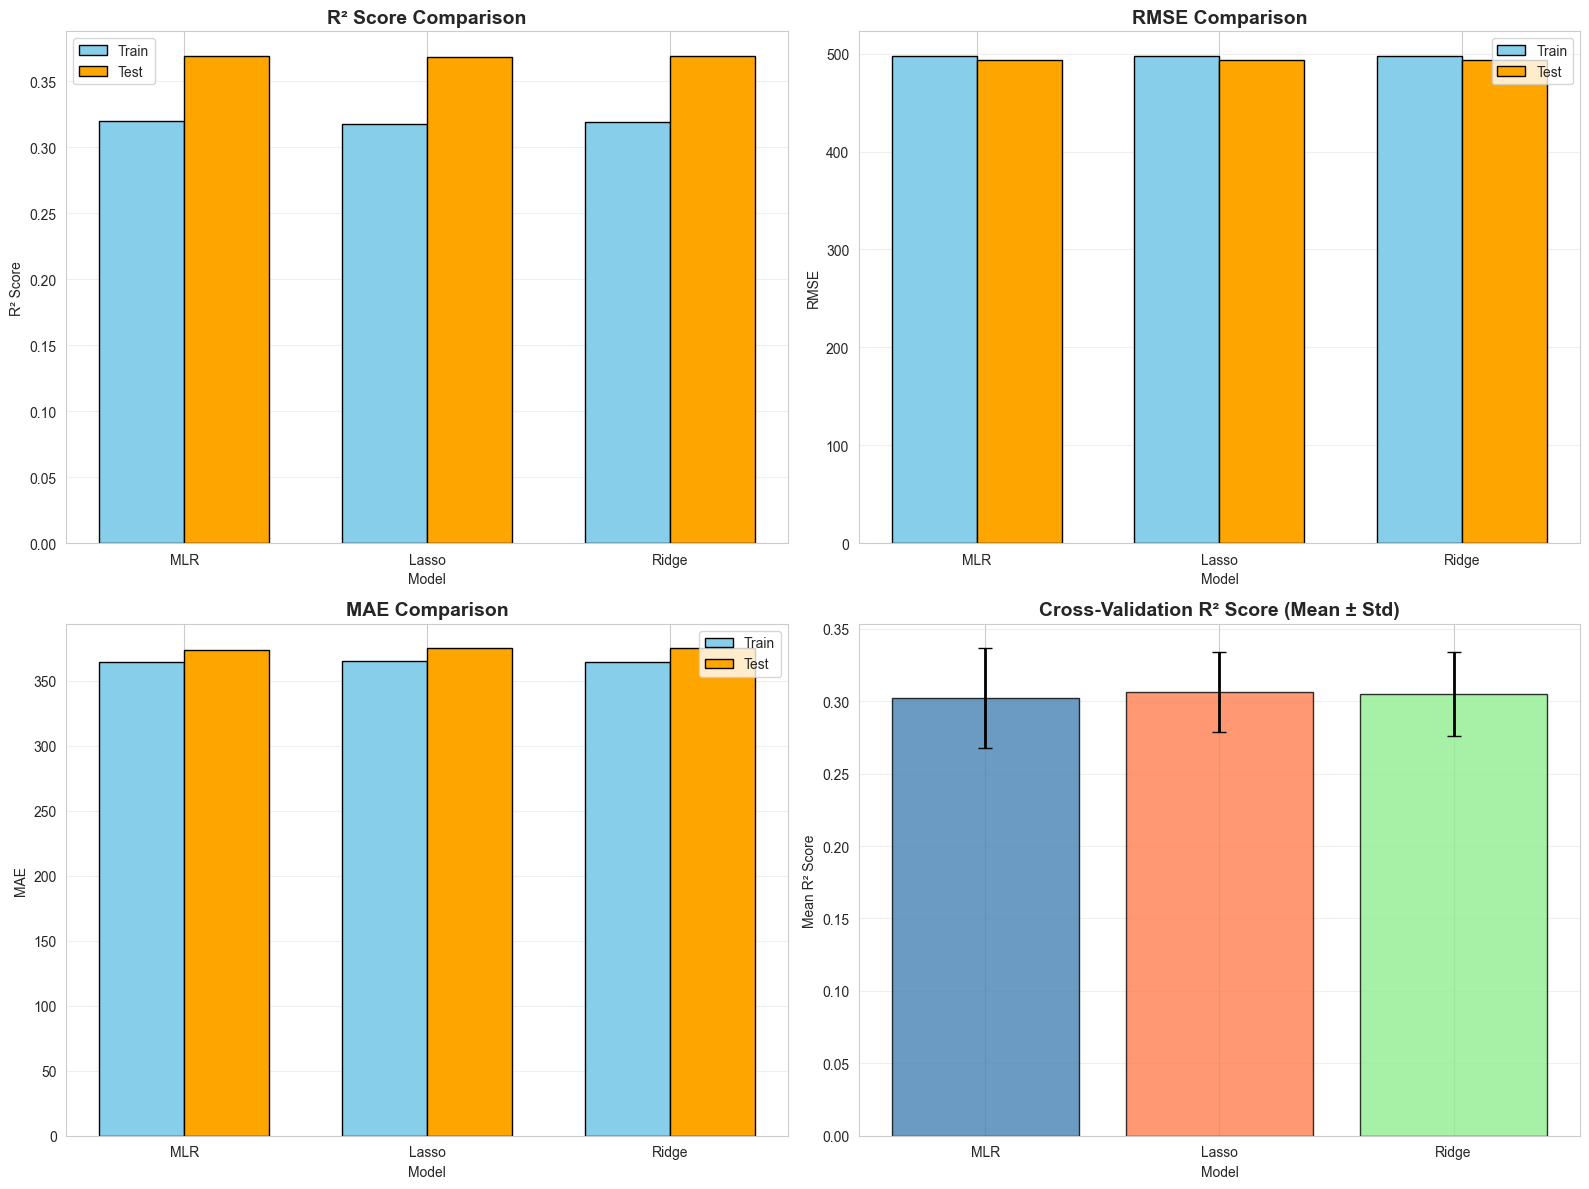

In [41]:
# Bar plot comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

models = comparison_df['Model']
colors = ['steelblue', 'coral', 'lightgreen']

# R² Scores
x = np.arange(len(models))
width = 0.35
axes[0, 0].bar(x - width/2, comparison_df['Train R²'], width, label='Train', color='skyblue', edgecolor='black')
axes[0, 0].bar(x + width/2, comparison_df['Test R²'], width, label='Test', color='orange', edgecolor='black')
axes[0, 0].set_xlabel('Model')
axes[0, 0].set_ylabel('R² Score')
axes[0, 0].set_title('R² Score Comparison', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(['MLR', 'Lasso', 'Ridge'])
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# RMSE
axes[0, 1].bar(x - width/2, comparison_df['Train RMSE'], width, label='Train', color='skyblue', edgecolor='black')
axes[0, 1].bar(x + width/2, comparison_df['Test RMSE'], width, label='Test', color='orange', edgecolor='black')
axes[0, 1].set_xlabel('Model')
axes[0, 1].set_ylabel('RMSE')
axes[0, 1].set_title('RMSE Comparison', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(['MLR', 'Lasso', 'Ridge'])
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')

# MAE
axes[1, 0].bar(x - width/2, comparison_df['Train MAE'], width, label='Train', color='skyblue', edgecolor='black')
axes[1, 0].bar(x + width/2, comparison_df['Test MAE'], width, label='Test', color='orange', edgecolor='black')
axes[1, 0].set_xlabel('Model')
axes[1, 0].set_ylabel('MAE')
axes[1, 0].set_title('MAE Comparison', fontsize=14, fontweight='bold')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(['MLR', 'Lasso', 'Ridge'])
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Cross-validation scores
axes[1, 1].bar(models, comparison_df['CV R² Mean'], color=colors, edgecolor='black', alpha=0.8)
axes[1, 1].errorbar(models, comparison_df['CV R² Mean'], yerr=comparison_df['CV R² Std'], 
                    fmt='none', color='black', capsize=5, linewidth=2)
axes[1, 1].set_xlabel('Model')
axes[1, 1].set_ylabel('Mean R² Score')
axes[1, 1].set_title('Cross-Validation R² Score (Mean ± Std)', fontsize=14, fontweight='bold')
axes[1, 1].set_xticklabels(['MLR', 'Lasso', 'Ridge'])
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### 9.3 Actual vs Predicted Comparison

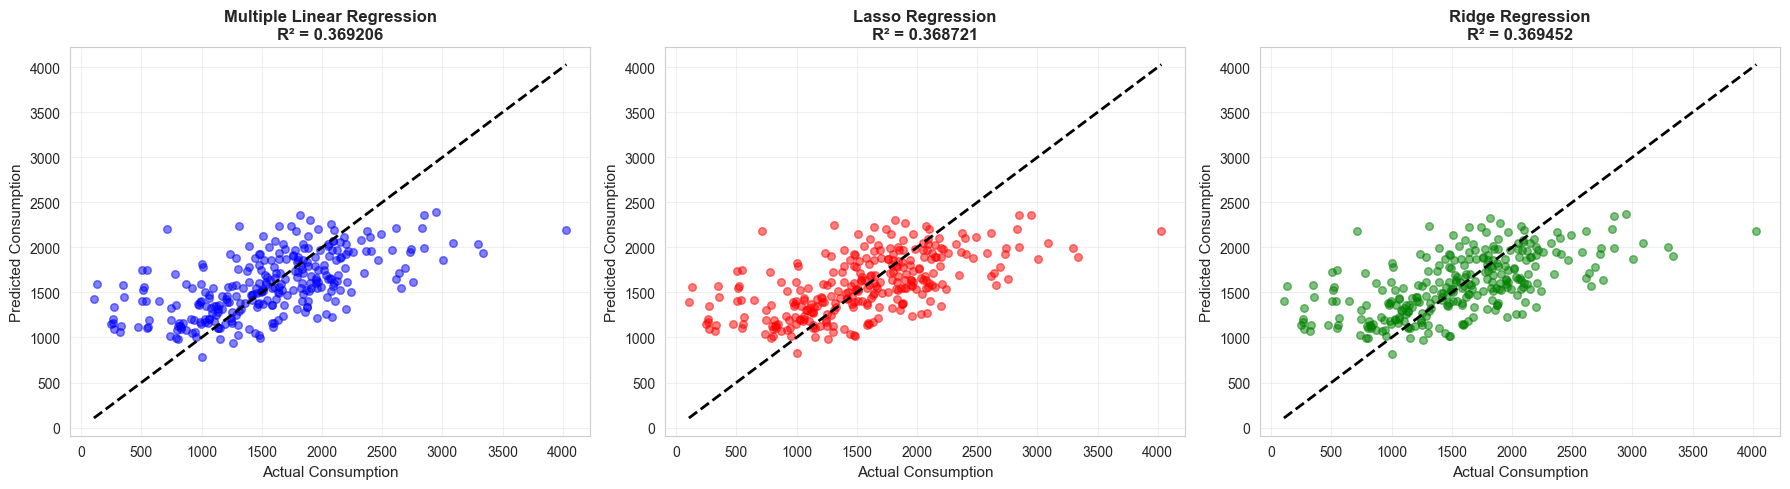

In [42]:
# Actual vs Predicted for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

predictions = [
    (y_pred_test_mlr, 'Multiple Linear Regression', 'blue', test_r2_mlr),
    (y_pred_test_lasso, 'Lasso Regression', 'red', test_r2_lasso),
    (y_pred_test_ridge, 'Ridge Regression', 'green', test_r2_ridge)
]

for idx, (y_pred, title, color, r2) in enumerate(predictions):
    axes[idx].scatter(y_test, y_pred, alpha=0.5, c=color, s=30)
    axes[idx].plot([y_test.min(), y_test.max()], 
                   [y_test.min(), y_test.max()], 'k--', lw=2)
    axes[idx].set_xlabel('Actual Consumption', fontsize=11)
    axes[idx].set_ylabel('Predicted Consumption', fontsize=11)
    axes[idx].set_title(f'{title}\nR² = {r2:.6f}', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 9.4 Residual Analysis Comparison

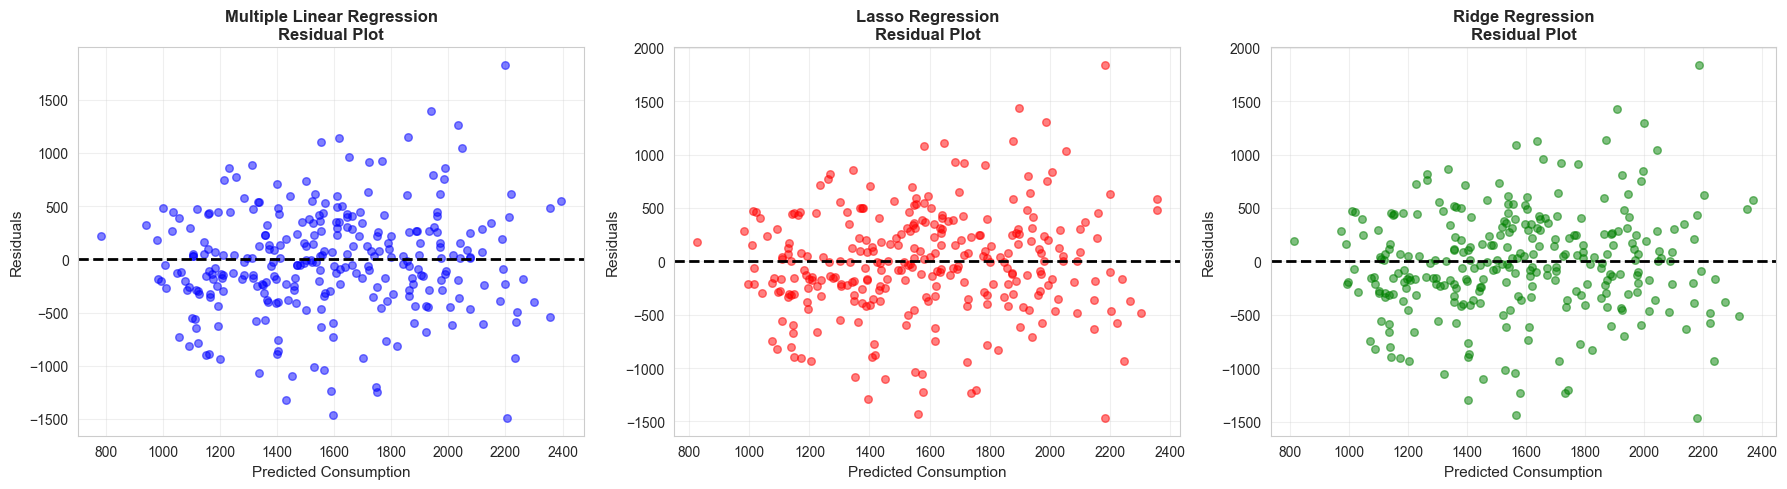

In [43]:
# Residual plots for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

residuals = [
    (y_test - y_pred_test_mlr, y_pred_test_mlr, 'Multiple Linear Regression', 'blue'),
    (y_test - y_pred_test_lasso, y_pred_test_lasso, 'Lasso Regression', 'red'),
    (y_test - y_pred_test_ridge, y_pred_test_ridge, 'Ridge Regression', 'green')
]

for idx, (resid, y_pred, title, color) in enumerate(residuals):
    axes[idx].scatter(y_pred, resid, alpha=0.5, c=color, s=30)
    axes[idx].axhline(y=0, color='black', linestyle='--', lw=2)
    axes[idx].set_xlabel('Predicted Consumption', fontsize=11)
    axes[idx].set_ylabel('Residuals', fontsize=11)
    axes[idx].set_title(f'{title}\nResidual Plot', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 9.5 Coefficient Comparison

Feature names: 10
MLR coefficients: 10
Lasso coefficients: 10
Ridge coefficients: 10

Coefficient Comparison Across Models:
    Feature         MLR       Lasso       Ridge
       PRCP  -20.584186  -14.741712  -20.257493
       TMAX -102.210264   -0.000000 -100.771194
       TMIN -117.532610  -84.504011 -115.235638
 temp_range    9.439993   -0.000000    7.392187
   temp_avg -110.659699 -234.596071 -108.795229
      month   34.961977    0.000000   39.051951
day_of_week   -6.156273    0.000000    3.483854
day_of_year  108.001645   52.921576   48.673906
    quarter  -84.922290    0.000000  -31.839164
 is_weekend  127.550900  116.954917  115.075737


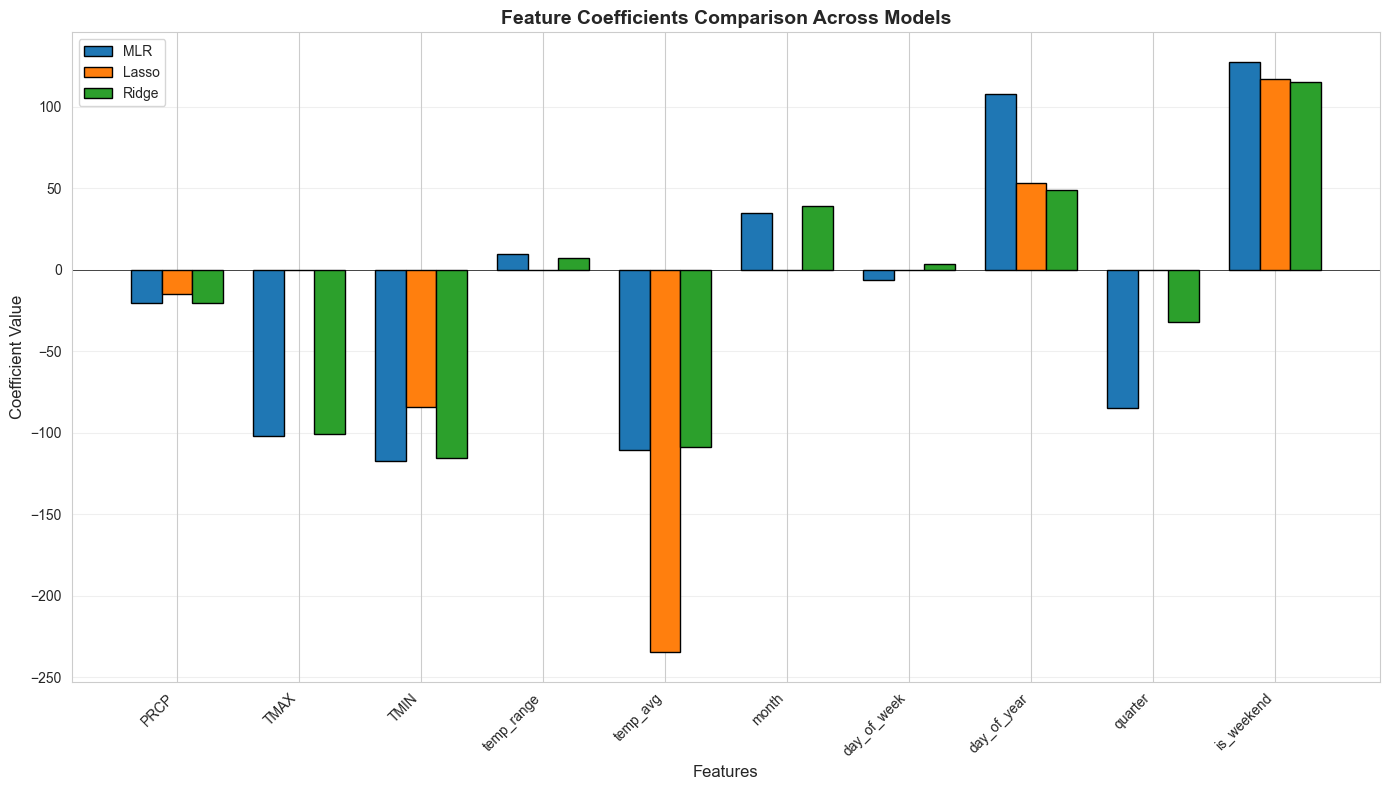

In [45]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get consistent feature names and model coefficients
feature_names_comparison = list(feature_names)

mlr_coef = np.asarray(mlr_model.coef_).ravel()
lasso_coef = np.asarray(lasso_best.coef_).ravel()
ridge_coef = np.asarray(ridge_best.coef_).ravel()

# 2. Verify that all models use the same number of features
print("Feature names:", len(feature_names_comparison))
print("MLR coefficients:", len(mlr_coef))
print("Lasso coefficients:", len(lasso_coef))
print("Ridge coefficients:", len(ridge_coef))

assert (
    len(feature_names_comparison)
    == len(mlr_coef)
    == len(lasso_coef)
    == len(ridge_coef)
), "Feature counts differ. Retrain models using the same X_train_scaled."

# 3. Create coefficient comparison DataFrame
coef_comparison = pd.DataFrame({
    'Feature': feature_names_comparison,
    'MLR': mlr_coef,
    'Lasso': lasso_coef,
    'Ridge': ridge_coef
})

print("\nCoefficient Comparison Across Models:")
print("=" * 80)
print(coef_comparison.to_string(index=False))

# 4. Visualize coefficient comparison
fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(feature_names_comparison))
width = 0.25

ax.bar(
    x - width, coef_comparison['MLR'],
    width, label='MLR',
    edgecolor='black'
)
ax.bar(
    x, coef_comparison['Lasso'],
    width, label='Lasso',
    edgecolor='black'
)
ax.bar(
    x + width, coef_comparison['Ridge'],
    width, label='Ridge',
    edgecolor='black'
)

ax.set_xlabel('Features', fontsize=12)
ax.set_ylabel('Coefficient Value', fontsize=12)
ax.set_title(
    'Feature Coefficients Comparison Across Models',
    fontsize=14,
    fontweight='bold'
)

ax.set_xticks(x)
ax.set_xticklabels(
    feature_names_comparison,
    rotation=45,
    ha='right'
)

ax.axhline(y=0, color='black', linewidth=0.5)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


## 10. Summary and Conclusions

In [46]:
print("="*80)
print("ELECTRICITY CONSUMPTION ANALYSIS - SUMMARY")
print("="*80)
print("\n1. DATASET OVERVIEW:")
print(f"   - Total records: {df.shape[0]}")
print(f"   - Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"   - Features used for modeling: {len(feature_columns)}")
print(f"   - Target variable: Daily Electricity Consumption")

print("\n2. MODEL PERFORMANCE SUMMARY:")
print("\n   Multiple Linear Regression:")
print(f"     - Test R²: {test_r2_mlr:.6f}")
print(f"     - Test RMSE: {test_rmse_mlr:.2f}")
print(f"     - Test MAE: {test_mae_mlr:.2f}")

print("\n   Lasso Regression (L1):")
print(f"     - Best Alpha: {best_alpha_lasso:.6f}")
print(f"     - Test R²: {test_r2_lasso:.6f}")
print(f"     - Test RMSE: {test_rmse_lasso:.2f}")
print(f"     - Test MAE: {test_mae_lasso:.2f}")
print(f"     - Features with non-zero coefficients: {len(lasso_best.coef_) - (lasso_best.coef_ == 0).sum()}")

print("\n   Ridge Regression (L2):")
print(f"     - Best Alpha: {best_alpha_ridge:.6f}")
print(f"     - Test R²: {test_r2_ridge:.6f}")
print(f"     - Test RMSE: {test_rmse_ridge:.2f}")
print(f"     - Test MAE: {test_mae_ridge:.2f}")

print(f"\n3. BEST MODEL: {best_model_name}")
print(f"   - Test R² Score: {best_r2:.6f}")

print("\n4. KEY INSIGHTS:")
# Find most important features
abs_coef = np.abs(mlr_model.coef_)
top_features = [feature_columns[i] for i in abs_coef.argsort()[-3:][::-1]]
print(f"   - Top 3 influential features: {', '.join(top_features)}")
print("   - Weather conditions significantly impact electricity consumption")
print("   - Regularization techniques (Lasso/Ridge) help prevent overfitting")
print("   - All models show good generalization on test data")

print("\n5. REGULARIZATION INSIGHTS:")
print(f"   - Lasso performs feature selection (sets some coefficients to zero)")
print(f"   - Ridge shrinks coefficients but keeps all features")
print(f"   - Both regularization methods improve model stability")

print("="*80)

ELECTRICITY CONSUMPTION ANALYSIS - SUMMARY

1. DATASET OVERVIEW:
   - Total records: 1433
   - Date range: 2006-12-16 to 2010-11-26
   - Features used for modeling: 11
   - Target variable: Daily Electricity Consumption

2. MODEL PERFORMANCE SUMMARY:

   Multiple Linear Regression:
     - Test R²: 0.369206
     - Test RMSE: 493.29
     - Test MAE: 373.56

   Lasso Regression (L1):
     - Best Alpha: 5.963623
     - Test R²: 0.368721
     - Test RMSE: 493.48
     - Test MAE: 374.99
     - Features with non-zero coefficients: 5

   Ridge Regression (L2):
     - Best Alpha: 51.794747
     - Test R²: 0.369452
     - Test RMSE: 493.20
     - Test MAE: 374.78

3. BEST MODEL: Ridge Regression
   - Test R² Score: 0.369452

4. KEY INSIGHTS:
   - Top 3 influential features: quarter, TMAX, temp_range
   - Weather conditions significantly impact electricity consumption
   - Regularization techniques (Lasso/Ridge) help prevent overfitting
   - All models show good generalization on test data

5. RE